# Clustering and Operating-State Identification

Compares K-Means and DBSCAN on the operating-region records (wind speed ≥ 3.5 m/s) and selects a normal-operation group for the regression stage.

**Inputs:** `out/01_preprocessing/` · **Outputs:** `out/02_clustering/` and `figures/fig6-2_dbscan_groups.png`.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.cluster import DBSCAN, KMeans
from sklearn.metrics import silhouette_score

IN_DIR = Path("../out/01_preprocessing")
OUT_DIR = Path("../out/02_clustering")
FIG_DIR = Path("../figures")
OUT_DIR.mkdir(parents=True, exist_ok=True)

RANDOM_STATE = 42
SILHOUETTE_SAMPLE = 10_000
K_VALUES = range(3, 7)
EPS_VALUES = [0.3, 0.5, 0.7, 0.9, 1.1]
MIN_SAMPLES = 10
CORE_FEATS = ["wind_speed_z", "power_kw_z", "power_ratio_z", "residual_kw_z"]
DIRECTION_FEATS = ["wd_sin", "wd_cos"]

COLOR_MAIN, COLOR_ALT, COLOR_MUTED = "#2a78d6", "#eb6834", "#8a8984"
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 200, "font.size": 10,
                     "axes.spines.top": False, "axes.spines.right": False})

features = pd.read_csv(IN_DIR / "wind_features.csv")
cluster_input = pd.read_csv(IN_DIR / "cluster_input_scaled.csv")
X_cluster = cluster_input[CORE_FEATS]

print("Features:", features.shape)
print("Cluster input:", cluster_input.shape)


def sampled_silhouette(X, labels):
    """Silhouette score on a fixed-size random sample (the full matrix is too slow)."""
    sample = X.sample(n=min(SILHOUETTE_SAMPLE, len(X)), random_state=RANDOM_STATE).index
    return silhouette_score(X.loc[sample], labels[sample])

Features: (50530, 21)
Cluster input: (40635, 8)


## 1. K-Means

`k` from 3 to 6 is tested on the core feature set, and again with `wd_sin` and `wd_cos` added, to check whether wind direction improves the separation (report Section 4.4). Both runs share the same sample and random state, so any difference comes from the direction features alone.

In [2]:
kmeans_labels = {}
rows = []
for k in K_VALUES:
    kmeans_labels[k] = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=20).fit_predict(X_cluster)
    rows.append({"method": "KMeans", "parameters": f"k={k}", "clusters": k, "noise_percent": 0.0,
                 "silhouette_score": sampled_silhouette(X_cluster, kmeans_labels[k])})
kmeans_results = pd.DataFrame(rows)
kmeans_results

,method,parameters,clusters,noise_percent,silhouette_score
0,KMeans,k=3,3,0.0,0.513458
1,KMeans,k=4,4,0.0,0.525215
2,KMeans,k=5,5,0.0,0.467754
3,KMeans,k=6,6,0.0,0.410633


In [3]:
X_extended = cluster_input[CORE_FEATS + DIRECTION_FEATS]
extended_scores = [
    sampled_silhouette(X_extended,
                       KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=20).fit_predict(X_extended))
    for k in K_VALUES
]
feature_set_comparison = pd.DataFrame({
    "k": list(K_VALUES),
    "silhouette_core": kmeans_results["silhouette_score"],
    "silhouette_with_direction": extended_scores,
})
feature_set_comparison

,k,silhouette_core,silhouette_with_direction
0,3,0.513458,0.384085
1,4,0.525215,0.389787
2,5,0.467754,0.381425
3,6,0.410633,0.407432


Adding direction lowers the silhouette score at every `k`, so the core feature set is kept. The best K-Means configuration is the `k` with the highest silhouette score.

In [4]:
best_k = int(kmeans_results.loc[kmeans_results["silhouette_score"].idxmax(), "clusters"])
print("Best K-Means k:", best_k)
print(pd.Series(kmeans_labels[best_k]).value_counts().sort_index())

Best K-Means k: 4
0    21701
1    15381
2     2266
3     1287
Name: count, dtype: int64


## 2. DBSCAN

DBSCAN groups dense observations and labels isolated ones as noise (`-1`). Noise is excluded from its silhouette score, which is undefined when fewer than two clusters are found.

In [5]:
dbscan_labels = {}
rows = []
for eps in EPS_VALUES:
    labels = DBSCAN(eps=eps, min_samples=MIN_SAMPLES, n_jobs=-1).fit_predict(X_cluster)
    dbscan_labels[eps] = labels
    clustered = labels != -1
    n_clusters = len(set(labels[clustered]))
    score = sampled_silhouette(X_cluster[clustered], labels) if n_clusters >= 2 else np.nan
    rows.append({"method": "DBSCAN", "parameters": f"eps={eps}, min_samples={MIN_SAMPLES}",
                 "clusters": n_clusters, "noise_percent": 100 * (~clustered).mean(),
                 "silhouette_score": score})
dbscan_results = pd.DataFrame(rows)
dbscan_results

,method,parameters,clusters,noise_percent,silhouette_score
0,DBSCAN,"eps=0.3, min_samples=10",4,0.243632,0.615082
1,DBSCAN,"eps=0.5, min_samples=10",1,0.024609,NaN
2,DBSCAN,"eps=0.7, min_samples=10",1,0.000000,NaN
3,DBSCAN,"eps=0.9, min_samples=10",1,0.000000,NaN
4,DBSCAN,"eps=1.1, min_samples=10",1,0.000000,NaN


## 3. Compare K-Means and DBSCAN

A high silhouette score is not useful on its own if nearly all records fall into one cluster, so cluster sizes are checked as well.

In [6]:
clustering_results = pd.concat([kmeans_results, dbscan_results], ignore_index=True)
clustering_results.sort_values("silhouette_score", ascending=False)

,method,parameters,clusters,noise_percent,silhouette_score
4,DBSCAN,"eps=0.3, min_samples=10",4,0.243632,0.615082
1,KMeans,k=4,4,0.000000,0.525215
0,KMeans,k=3,3,0.000000,0.513458
2,KMeans,k=5,5,0.000000,0.467754
3,KMeans,k=6,6,0.000000,0.410633
5,DBSCAN,"eps=0.5, min_samples=10",1,0.024609,NaN
6,DBSCAN,"eps=0.7, min_samples=10",1,0.000000,NaN
7,DBSCAN,"eps=0.9, min_samples=10",1,0.000000,NaN
8,DBSCAN,"eps=1.1, min_samples=10",1,0.000000,NaN


In [7]:
best_eps = EPS_VALUES[int(dbscan_results["silhouette_score"].idxmax())]
cluster_input["cluster"] = dbscan_labels[best_eps]

group_sizes = cluster_input["cluster"].value_counts().sort_index()
print(f"Selected DBSCAN eps: {best_eps}")
print(group_sizes)
print(f"Largest cluster holds {group_sizes.max() / len(cluster_input):.1%} of operating-region records")

Selected DBSCAN eps: 0.3
cluster
-1       99
 0    40476
 1       42
 2       10
 3        8
Name: count, dtype: int64
Largest cluster holds 99.6% of operating-region records


## 4. Apply cluster labels to the full dataset

Labels are joined back to all 50,530 records through `row_id`: `-2` = below the operating range, `-1` = DBSCAN noise, non-negative = DBSCAN cluster.

In [8]:
features["cluster"] = -2
features.loc[cluster_input["row_id"], "cluster"] = cluster_input["cluster"].to_numpy()
features["cluster_state"] = (features["cluster"].astype(str)
                             .replace({"-2": "below_operating_range", "-1": "dbscan_noise"}))
features["cluster_state"].value_counts()

cluster_state
0                        40476
below_operating_range     9895
dbscan_noise                99
1                           42
2                           10
3                            8
Name: count, dtype: int64

## 5. Interpret the clusters

In [9]:
cluster_summary = (
    features[features["cluster"] >= 0]
    .groupby("cluster")
    .agg(records=("cluster", "size"),
         median_power_kw=("power_kw", "median"),
         median_power_ratio=("power_ratio", "median"),
         median_residual_kw=("residual_kw", "median"),
         mean_power_ratio=("power_ratio", "mean"),
         total_shortfall_mwh=("shortfall_kwh", lambda s: s.sum() / 1000))
    .sort_values("median_power_ratio", ascending=False)
)
cluster_summary

,records,median_power_kw,median_power_ratio,median_residual_kw,mean_power_ratio,total_shortfall_mwh
cluster,,,,,,
0,40476,1340.328980,0.893433,105.484484,0.836309,1533.391378
2,10,980.303223,0.272306,2619.696777,0.263647,4.418120
3,8,765.535156,0.212649,2834.464844,0.212007,3.782366
1,42,384.966507,0.106935,3208.862000,0.112522,22.319044


The rule-based states are a reference for interpreting the clusters, not training labels.

In [10]:
pd.crosstab(features["cluster_state"], features["rule_state"], normalize="index").round(3)

rule_state,below_operating_range,near_curve,underperforming,zero_output
cluster_state,,,,
0,0.0,0.771,0.175,0.055
1,0.0,0.000,1.000,0.000
2,0.0,0.000,1.000,0.000
3,0.0,0.000,1.000,0.000
below_operating_range,1.0,0.000,0.000,0.000
dbscan_noise,0.0,0.061,0.929,0.010


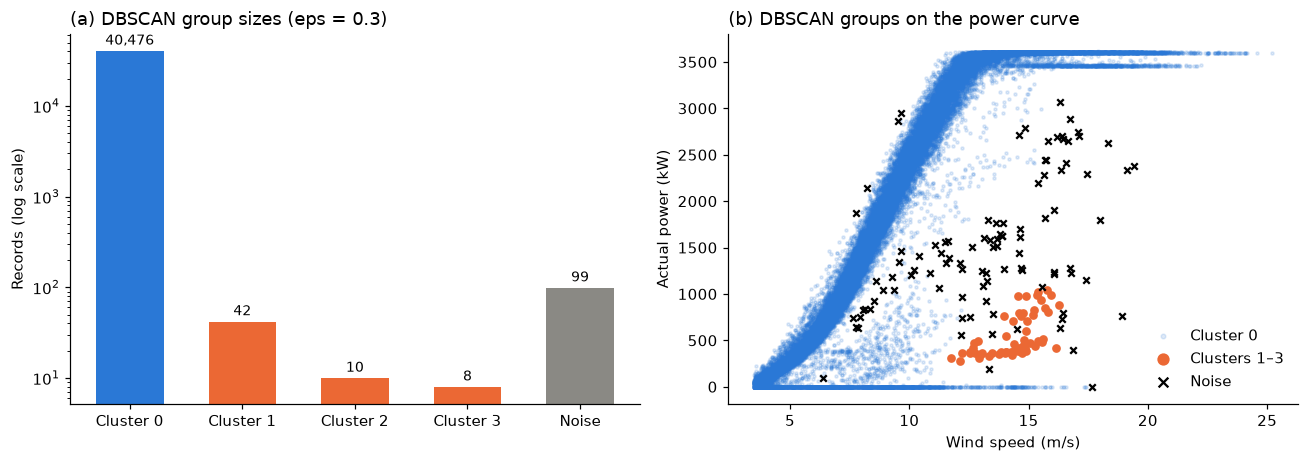

In [11]:
operating = features[features["in_operating_region"]]
noise = operating["cluster"] == -1
minor = operating["cluster"] > 0

labels_plot = [f"Cluster {c}" if c >= 0 else "Noise" for c in list(group_sizes.index[1:]) + [-1]]
sizes_plot = list(group_sizes.iloc[1:]) + [group_sizes.loc[-1]]
colors_plot = [COLOR_MAIN] + [COLOR_ALT] * (len(sizes_plot) - 2) + [COLOR_MUTED]

fig, axes = plt.subplots(1, 2, figsize=(12, 4.3))
ax = axes[0]
bars = ax.bar(labels_plot, sizes_plot, color=colors_plot, width=0.6)
ax.bar_label(bars, labels=[f"{n:,}" for n in sizes_plot], padding=2, fontsize=9)
ax.set_yscale("log")
ax.set_ylabel("Records (log scale)")
ax.set_title(f"(a) DBSCAN group sizes (eps = {best_eps})", loc="left")

ax = axes[1]
main = operating[~noise & ~minor]
ax.scatter(main["wind_speed"], main["power_kw"], s=4, alpha=0.15, color=COLOR_MAIN,
           label="Cluster 0", rasterized=True)
ax.scatter(operating.loc[minor, "wind_speed"], operating.loc[minor, "power_kw"], s=22, color=COLOR_ALT,
           label=f"Clusters 1–{operating['cluster'].max()}")
ax.scatter(operating.loc[noise, "wind_speed"], operating.loc[noise, "power_kw"], s=18, color="black",
           marker="x", label="Noise")
ax.set_xlabel("Wind speed (m/s)")
ax.set_ylabel("Actual power (kW)")
ax.set_title("(b) DBSCAN groups on the power curve", loc="left")
ax.legend(frameon=False, loc="lower right", markerscale=1.5)
fig.tight_layout()
fig.savefig(FIG_DIR / "fig6-2_dbscan_groups.png")
plt.show()

## 6. Select the normal-operation cluster

The cluster with the highest median power ratio is taken as normal operation. It is chosen by behaviour, not by its label. Its make-up by rule-based state shows how many stops and low-output records it still contains.

In [12]:
normal_cluster = int(cluster_summary["median_power_ratio"].idxmax())
print("Selected normal cluster:", normal_cluster)
features.loc[features["cluster"] == normal_cluster, "rule_state"].value_counts(normalize=True).round(3)

Selected normal cluster: 0


rule_state
near_curve         0.771
underperforming    0.175
zero_output        0.055
Name: proportion, dtype: float64

In [13]:
features.to_csv(OUT_DIR / "wind_features_clustered.csv", index=False)
cluster_input.to_csv(OUT_DIR / "cluster_input_dbscan.csv", index=False)
clustering_results.to_csv(OUT_DIR / "clustering_comparison.csv", index=False)
feature_set_comparison.to_csv(OUT_DIR / "feature_set_comparison.csv", index=False)
print("Saved:", *sorted(p.name for p in OUT_DIR.iterdir()), sep="\n  ")

Saved:
  cluster_input_dbscan.csv
  clustering_comparison.csv
  feature_set_comparison.csv
  wind_features_clustered.csv


## Summary

- DBSCAN (`eps=0.3`, `min_samples=10`) has the highest silhouette score, but one cluster holds almost every operating-region record, so it barely separates operating states.
- That dominant cluster is used as the normal-operation group for regression (`cluster == 0` in `wind_features_clustered.csv`).
- Clusters are inferred operating states, not confirmed faults.